# Flight and Airport Analytics - ETL verification and Exploratory Data Analysis

**Course:** Programming for AI - ETL + EDA Pipeline (CLO2)  
**Data source:** AviationStack `/v1/flights` REST API -> Pydantic -> pandas -> SQLite  

This notebook starts **from the SQLite database** that the ETL pipeline filled (never from an in-memory API response), so the analysis describes exactly the records that were validated and stored. Every statistic below is computed when the notebook runs; interpretation sentences are generated from those numbers.

**Contents**  
1. Setup and database connection  
2. ETL audit - runs, rejected records, integrity checks, schema  
3. A data-quality discovery: what the API's `+00:00` timestamps really mean  
4. EDA - overview, quality, descriptive statistics  
5. EDA - distributions, trends, relationships, comparisons, outliers  
6. Findings and limitations

## 1. Setup and database connection

In [1]:
import io, json, sys
from pathlib import Path

import matplotlib
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config, database, eda, eda_charts, data_processor

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)

def show(fig, dpi=110):
    """Render a Matplotlib figure inline."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, facecolor=fig.get_facecolor())
    display(Image(buf.getvalue()))

print("Project root :", ROOT)
print("Database     :", config.DATABASE_PATH)
print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Project root : /home/claude/work
Database     : /home/claude/work/database/flight_airport.db
pandas 3.0.2 | matplotlib 3.10.8


## 2. ETL audit - what the pipeline did

### 2.1 Pipeline runs (`refresh_log` table)
Runs 1-5 were live API retrievals made while developing the project (run 4 failed with HTTP 403). Runs 6-9 rebuilt the flights table from the four archived raw responses with the final pipeline.

In [2]:
history = database.fetch_run_history()
history[["id", "refreshed_at", "source", "records_fetched", "records_valid",
         "records_rejected", "records_inserted", "records_updated", "status"]]

,id,refreshed_at,source,records_fetched,records_valid,records_rejected,records_inserted,records_updated,status
0,1,2026-10-09 05:15:17 UTC,aviationstack/flights,100,100,0,0,0,success
1,2,2026-10-09 05:21:10 UTC,aviationstack/flights,25,25,0,0,0,success
2,3,2026-10-09 05:22:57 UTC,aviationstack/flights,10,10,0,0,0,success
3,4,2026-10-11 06:59:06 UTC,aviationstack/flights,0,0,0,0,0,failed
4,5,2026-10-13 01:43:09 UTC,aviationstack/flights,100,100,0,0,0,success
5,6,2026-10-17 12:31:27 UTC,raw_replay:flights_raw_20261009_101516.json,100,100,0,100,0,success
6,7,2026-10-17 12:31:27 UTC,raw_replay:flights_raw_20261009_102110.json,25,25,0,24,1,success
7,8,2026-10-17 12:31:27 UTC,raw_replay:flights_raw_20261009_102257.json,10,10,0,9,1,success
8,9,2026-10-17 12:31:27 UTC,raw_replay:flights_raw_20261013_064308.json,100,97,3,97,0,partial


### 2.2 Rejected records (`rejected_records` table)
Every record that failed Pydantic validation is kept with the field that failed and the reason.

In [3]:
rej = database.fetch_rejected()
display(rej[["run_id", "stage", "record_index", "identifier", "error_fields", "error_messages"]])
print(f"{len(rej)} rejected records in total")

,run_id,stage,record_index,identifier,error_fields,error_messages
0,9,extract,10,row 10,record,"flight has no IATA code, ICAO code or number - cannot be identified"
1,9,extract,11,row 11,record,"flight has no IATA code, ICAO code or number - cannot be identified"
2,9,extract,12,row 12,record,"flight has no IATA code, ICAO code or number - cannot be identified"


3 rejected records in total


### 2.3 Integrity checks run as SQL against the stored data

In [4]:
checks = database.verify_database()
pd.Series(checks, name="value").to_frame()

,value
schema_version,2
integrity_check,ok
foreign_key_violations,0
flights,230
duplicate_natural_keys,0
rows_missing_identity,0
invalid_status_rows,0
negative_delay_rows,0
airport_sightings,460
airport_sightings_expected,460


### 2.4 Database schema

In [5]:
for table, cols in database.schema_description().items():
    print(f"\n{table}")
    print(pd.DataFrame(cols).to_string(index=False))


airports
        name    type  notnull  primary_key
          id INTEGER    False         True
        iata    TEXT     True        False
        icao    TEXT    False        False
airport_name    TEXT    False        False
    timezone    TEXT    False        False
  departures INTEGER    False        False
    arrivals INTEGER    False        False
   sightings INTEGER    False        False

flights
                  name    type  notnull  primary_key
                    id INTEGER    False         True
           flight_date    TEXT     True        False
         flight_status    TEXT     True        False
           flight_iata    TEXT     True        False
           flight_icao    TEXT    False        False
         flight_number    TEXT    False        False
          airline_name    TEXT    False        False
          airline_iata    TEXT    False        False
          airline_icao    TEXT    False        False
           dep_airport    TEXT    False        False
           

### 2.5 Re-running the pipeline does not duplicate data
The cell replays the four raw responses a second time into a **scratch copy** of the database and compares row counts.

In [6]:
import shutil, tempfile
from src import pipeline

scratch = Path(tempfile.mkdtemp()) / "scratch.db"
shutil.copy(config.DATABASE_PATH, scratch)
before = database.count_rows("flights", scratch)
rows = []
for r in pipeline.replay_raw_files(sorted(config.DATA_RAW_DIR.glob("*.json")),
                                   db_path=scratch, save_artifacts=False):
    rows.append({"raw file": Path(r.raw_file).name, "extracted": r.extracted,
                 "accepted": r.accepted, "inserted": r.inserted, "updated": r.updated})
display(pd.DataFrame(rows))
after = database.count_rows("flights", scratch)
print(f"flights before replay: {before}   after replay: {after}   new duplicates: {after - before}")
print("integrity checks passed:", database.verify_database(scratch)["all_checks_passed"])

,raw file,extracted,accepted,inserted,updated
0,flights_raw_20261009_101516.json,100,100,0,100
1,flights_raw_20261009_102110.json,25,25,0,25
2,flights_raw_20261009_102257.json,10,10,0,10
3,flights_raw_20261013_064308.json,100,97,0,97


flights before replay: 230   after replay: 230   new duplicates: 0
integrity checks passed: True


## 3. A data-quality discovery: the API's `+00:00` timestamps

AviationStack writes flight times such as `2026-10-09T13:00:00+00:00`, which looks like UTC. **It is not.** For flights that carry both `live.updated` (a genuine UTC instant) and a departure `actual` time, the check below compares the two possible readings. A correct reading must place `live.updated` *after* departure.

In [7]:
payloads = [json.loads(p.read_text(encoding="utf-8")) for p in sorted(config.DATA_RAW_DIR.glob("*.json"))]
evidence = eda.timestamp_semantics_check(payloads)
display(evidence)
lit, wall = evidence["minutes_after_departure_literal"], evidence["minutes_after_departure_wallclock"]
display(Markdown(
    f"**{len(evidence)} flights tested.** Trusting the `+00:00` suffix puts the live-position report "
    f"between **{lit.max()}** and **{lit.min()}** minutes *relative to departure* (i.e. hours *before* the aircraft left - impossible). "
    f"Reading the digits as the departure airport's local time puts it **{wall.min()} to {wall.max()} minutes after** departure - consistent. "
    "The pipeline therefore converts every flight time from airport-local to true UTC using the airport's timezone "
    "(`src/timeutils.py`). Limitation: the tested flights depart from "
    f"{', '.join(sorted(evidence['dep_timezone'].str.split('/').str[0].unique()))} "
    f"(UTC offsets of {sorted({round(pd.Timestamp('2026-10-09', tz=z).utcoffset().total_seconds()/3600, 1) for z in evidence['dep_timezone'].unique()})} h), "
    "so the proof covers those offsets; the conversion is applied to all airports on the strength of the same API behaviour, "
    "supported by plausible corrected durations (section 5.6)."))

,flight,dep_airport,dep_timezone,minutes_after_departure_literal,minutes_after_departure_wallclock
0,2P2919,MNL,Asia/Manila,-443,37
1,2P2959,MNL,Asia/Manila,-441,39
2,2P2141,MNL,Asia/Manila,-432,48
3,KT164,KUL,Asia/Kuala_Lumpur,-444,36
4,JL552,AKJ,Asia/Tokyo,-508,32
5,JL562,MMB,Asia/Tokyo,-506,34
6,JL584,HKD,Asia/Tokyo,-500,40
7,JL492,KCZ,Asia/Tokyo,-497,43
8,JL476,TAK,Asia/Tokyo,-503,37
9,JL627,HND,Asia/Tokyo,-522,18


**11 flights tested.** Trusting the `+00:00` suffix puts the live-position report between **-432** and **-522** minutes *relative to departure* (i.e. hours *before* the aircraft left - impossible). Reading the digits as the departure airport's local time puts it **18 to 48 minutes after** departure - consistent. The pipeline therefore converts every flight time from airport-local to true UTC using the airport's timezone (`src/timeutils.py`). Limitation: the tested flights depart from Asia (UTC offsets of [8.0, 9.0] h), so the proof covers those offsets; the conversion is applied to all airports on the strength of the same API behaviour, supported by plausible corrected durations (section 5.6).

## 4. EDA - overview, quality and descriptive statistics

In [8]:
df = eda.load_dataset()                    # <- read from SQLite
summary = eda.build_summary(df)
prof = eda.dataset_profile(df)
print(f"Dimensions : {prof['rows']} rows x {prof['columns']} columns")
print(f"Date range : {prof['date_min']} to {prof['date_max']}  ({prof['capture_dates']} distinct flight dates)")
print(f"Memory     : {prof['memory_kb']} KB")
print("dtypes     :", prof["dtype_counts"])

Dimensions : 230 rows x 47 columns
Date range : 2026-10-09 to 2026-10-13  (3 distinct flight dates)
Memory     : 348.5 KB
dtypes     : {'str': 26, 'float64': 9, 'datetime64[us, UTC]': 6, 'int64': 3, 'bool': 2, 'datetime64[us]': 1}


### 4.1 Data types, non-null counts and unique values

In [9]:
prof["dtype_table"]

,column,dtype,non_null,missing_pct,unique
0,id,int64,230,0.0,230
1,flight_date,datetime64[us],230,0.0,3
2,flight_status,str,230,0.0,3
3,flight_iata,str,230,0.0,230
4,flight_icao,str,230,0.0,230
5,flight_number,str,229,0.4,227
6,airline_name,str,230,0.0,101
7,airline_iata,str,227,1.3,99
8,airline_icao,str,230,0.0,103
9,dep_airport,str,227,1.3,51


### 4.2 Missing values

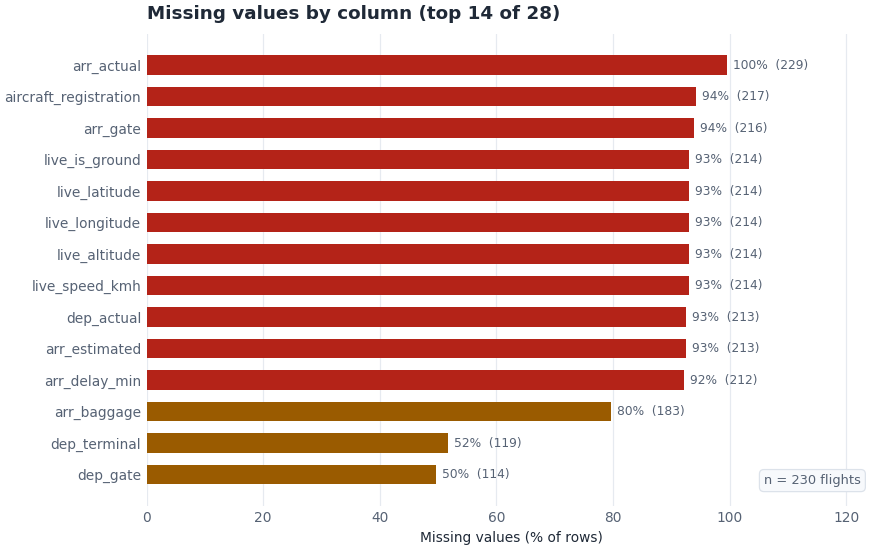

,column,missing,missing_pct
0,arr_actual,229,99.6
1,aircraft_registration,217,94.3
2,arr_gate,216,93.9
3,live_is_ground,214,93.0
4,live_latitude,214,93.0
5,live_longitude,214,93.0
6,live_altitude,214,93.0
7,live_speed_kmh,214,93.0
8,dep_actual,213,92.6
9,arr_estimated,213,92.6


In [10]:
show(eda_charts.fig_missing_values(df, summary))
summary["missing"]

In [11]:
cov = summary["delay_coverage"]
display(Markdown(
    f"**Reading the table.** Gate/terminal/aircraft and live-tracking fields are mostly empty presumably because the API fills them "
    f"only when that information exists (e.g. for tracked or boarding flights). Most important for this analysis: only **{cov['delay_reported']} of {cov['flights']}** flights "
    f"({cov['delay_reported_pct']}%) carry a delay value. A missing delay is **not** treated as 'on time' and is **not** imputed as 0."))

**Reading the table.** Gate/terminal/aircraft and live-tracking fields are mostly empty presumably because the API fills them only when that information exists (e.g. for tracked or boarding flights). Most important for this analysis: only **125 of 230** flights (54.3%) carry a delay value. A missing delay is **not** treated as 'on time' and is **not** imputed as 0.

### 4.3 Duplicates and constant columns

In [12]:
print(summary["duplicates"])
print("constant columns:", summary["constant_columns"])

{'exact_duplicate_rows': 0, 'natural_key_duplicates': 0, 'unique_flight_codes': 230}
constant columns: ['first_seen_at', 'updated_at']


### 4.4 Descriptive statistics

In [13]:
summary["numeric"]

,column,count,mean,std,min,25%,median,75%,max,skew
0,dep_delay_min,125.0,3.96,10.94,0.0,0.00,0.00,0.00,68.0,4.19
1,arr_delay_min,18.0,0.72,2.27,0.0,0.00,0.00,0.00,9.0,3.37
2,max_delay_min,125.0,3.96,10.94,0.0,0.00,0.00,0.00,68.0,4.19
3,scheduled_duration_min,187.0,180.43,132.99,20.0,92.50,135.00,235.00,735.0,1.83
4,live_speed_kmh,16.0,637.31,291.01,0.0,590.11,783.13,823.21,829.7,-1.58
5,live_altitude,16.0,7341.40,4065.19,0.0,5450.20,8450.58,10439.40,11574.8,-0.96


In [14]:
summary["categorical"]

,column,unique,top_value,top_count,top_share_pct
0,flight_status,3,scheduled,184,80.0
1,airline_name,101,Japan Airlines,12,5.2
2,dep_iata,53,TFU,28,12.2
3,arr_iata,99,SAI,16,7.0
4,route,127,BKK-SAI,14,6.1
5,dep_timezone,26,Asia/Shanghai,48,20.9


## 5. EDA - distributions, trends, relationships, comparisons, outliers

### 5.1 Distributions - categories

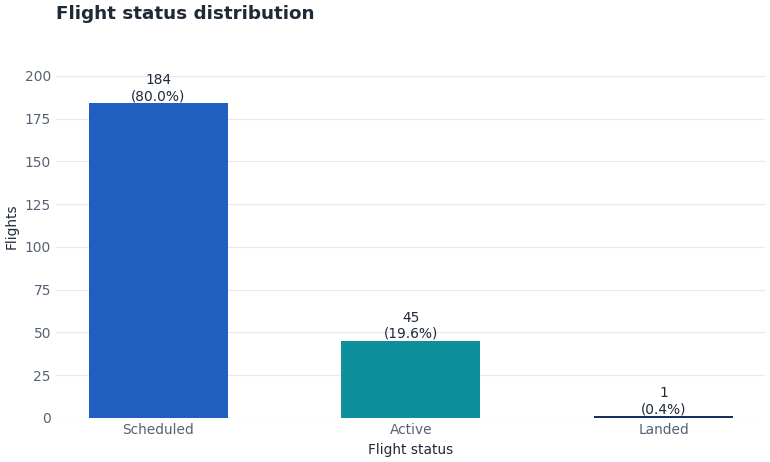

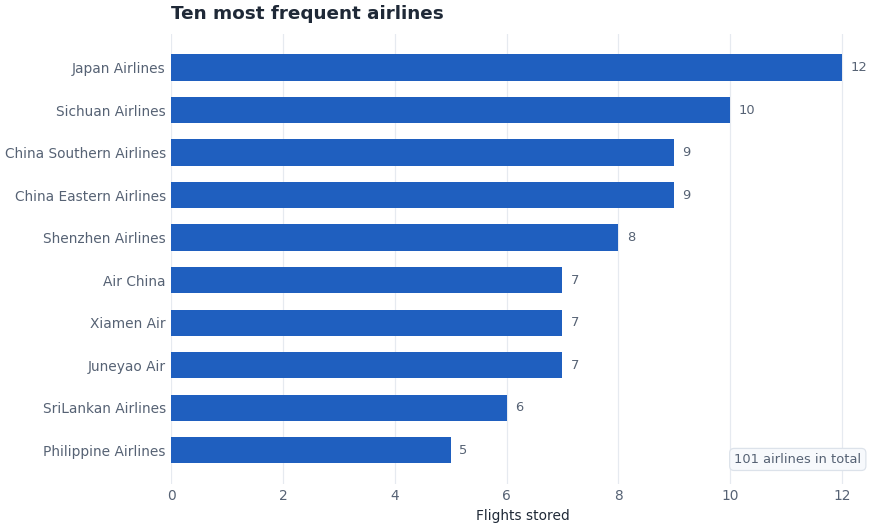

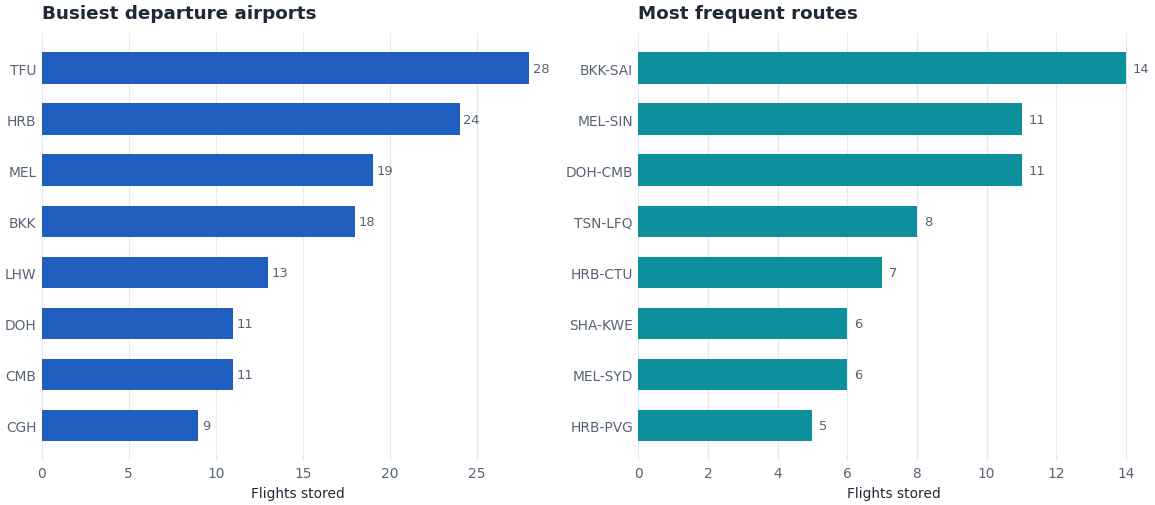

In [15]:
show(eda_charts.fig_status(df, summary))
show(eda_charts.fig_top_airlines(df, summary))
show(eda_charts.fig_top_routes_airports(df, summary))

### 5.2 Distributions - numeric

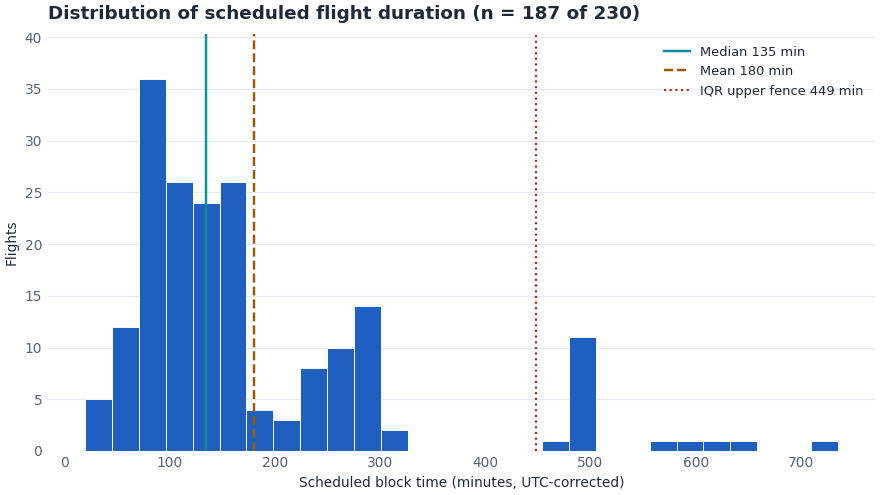

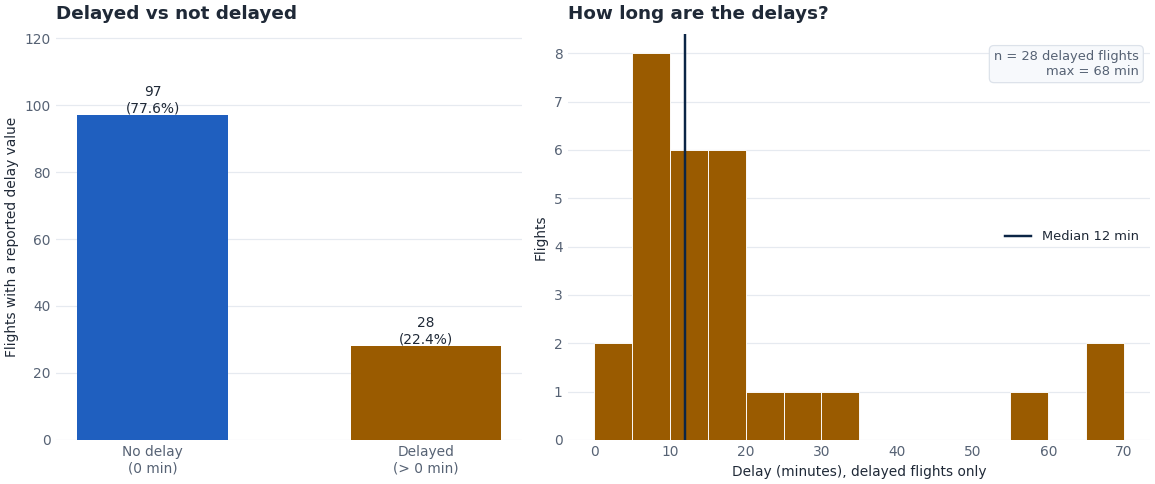

In [16]:
show(eda_charts.fig_duration(df, summary))
show(eda_charts.fig_delay(df, summary))

In [17]:
d = df["max_delay_min"].dropna(); pos = d[d > 0]
display(Markdown(
    f"**Interpretation.** Of {len(d)} flights with delay data, {len(pos)} ({100*len(pos)/len(d):.1f}%) were delayed. "
    f"The median over all of them is {d.median():.0f} min but the mean is {d.mean():.1f} min because a few long delays "
    f"(max {d.max():.0f} min) pull it up (skew {d.skew():.1f}); the median of the delayed flights alone is {pos.median():.0f} min. "
    "Operationally this means: most flights leave on time, delays are usually short, and rare long delays dominate averages - "
    "so the median and the share delayed are better summaries than the mean."))

**Interpretation.** Of 125 flights with delay data, 28 (22.4%) were delayed. The median over all of them is 0 min but the mean is 4.0 min because a few long delays (max 68 min) pull it up (skew 4.2); the median of the delayed flights alone is 12 min. Operationally this means: most flights leave on time, delays are usually short, and rare long delays dominate averages - so the median and the share delayed are better summaries than the mean.

### 5.3 Trends
The data covers only a few capture dates, so a time trend cannot be established; the date view is shown to make that limitation explicit. The hour-of-day view uses **airport-local** departure hour.

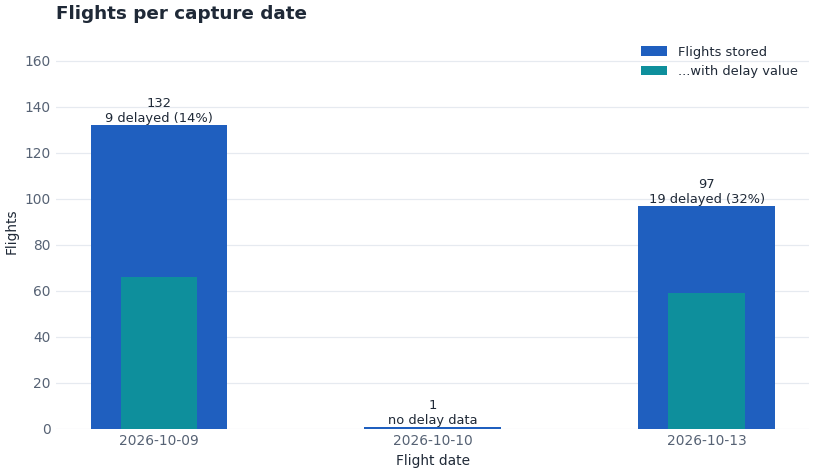

,date,flights,delay_reported,delayed,mean_delay_min,delayed_pct_of_reported
0,2026-10-09,132,66,9,2.45,13.6
1,2026-10-10,1,0,0,NaN,NaN
2,2026-10-13,97,59,19,5.64,32.2


In [18]:
show(eda_charts.fig_trend_dates(df, summary))
summary["trend_by_date"]

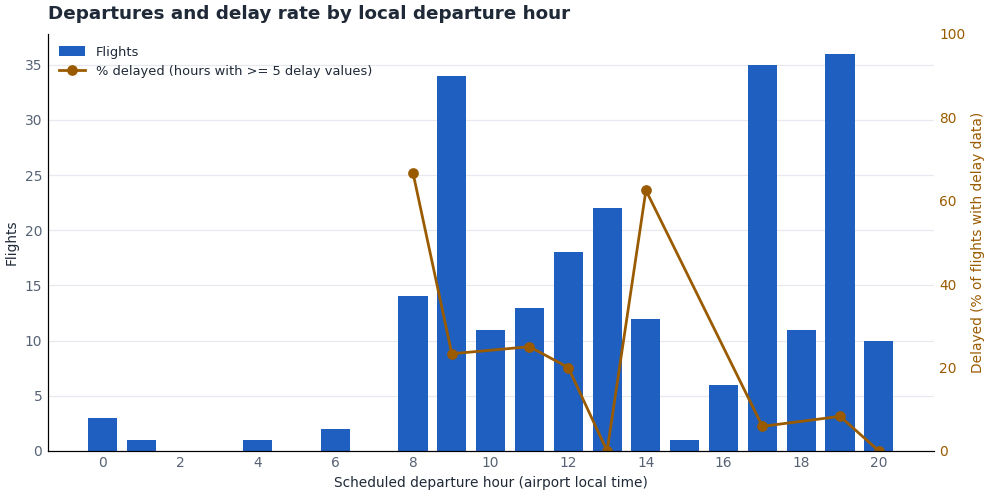

,dep_hour_local,flights,delay_reported,delayed,mean_delay_min,delayed_pct_of_reported
0,0,3,1,1,27.00,100.0
1,1,1,0,0,NaN,NaN
2,4,1,0,0,NaN,NaN
3,6,2,0,0,NaN,NaN
4,8,14,12,8,7.50,66.7
5,9,34,30,7,3.37,23.3
6,10,11,4,2,4.00,50.0
7,11,13,8,2,9.25,25.0
8,12,18,5,1,11.00,20.0
9,13,22,21,0,0.00,0.0


In [19]:
show(eda_charts.fig_hourly(df, summary))
summary["hourly"]

### 5.4 Relationships

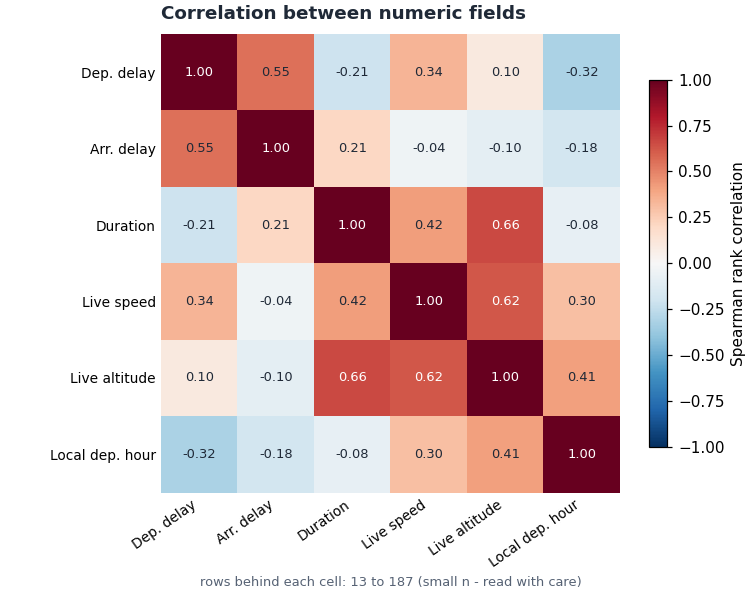

,dep_delay_min,arr_delay_min,scheduled_duration_min,live_speed_kmh,live_altitude,dep_hour_local
dep_delay_min,125,18,112,16,16,125
arr_delay_min,18,18,15,13,13,18
scheduled_duration_min,112,15,187,14,14,187
live_speed_kmh,16,13,14,16,16,16
live_altitude,16,13,14,16,16,16
dep_hour_local,125,18,187,16,16,230


In [20]:
show(eda_charts.fig_correlation(df, summary))
cols = list(summary["correlation_spearman"].columns)
eda.pairwise_counts(df, cols)

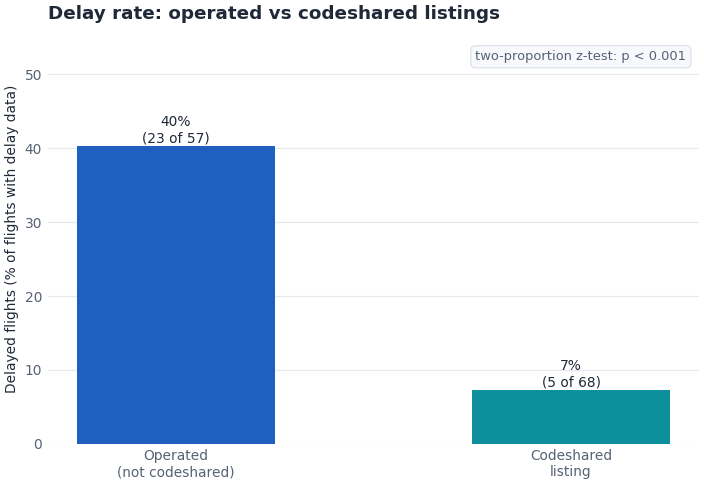

{'groups': {'operated': {'n': 57, 'delayed': 23}, 'codeshared': {'n': 68, 'delayed': 5}}, 'test': {'p1': 0.4035, 'p2': 0.0735, 'z': 4.407, 'p_value': 0.0}}


In [21]:
show(eda_charts.fig_codeshare(df, summary))
cs = summary["codeshare_vs_delay"]; print(cs)

Spearman (rank) correlation is used because delays are heavily skewed. The second table gives the number of rows behind every cell - correlations involving live-tracking fields rest on very few flights and should not be over-read. The codeshare comparison is an *association*: codeshare rows are marketing listings of a partner airline's flight, so they duplicate physical flights and may carry delay values differently. It is not evidence that codesharing reduces delays.

### 5.5 Comparisons

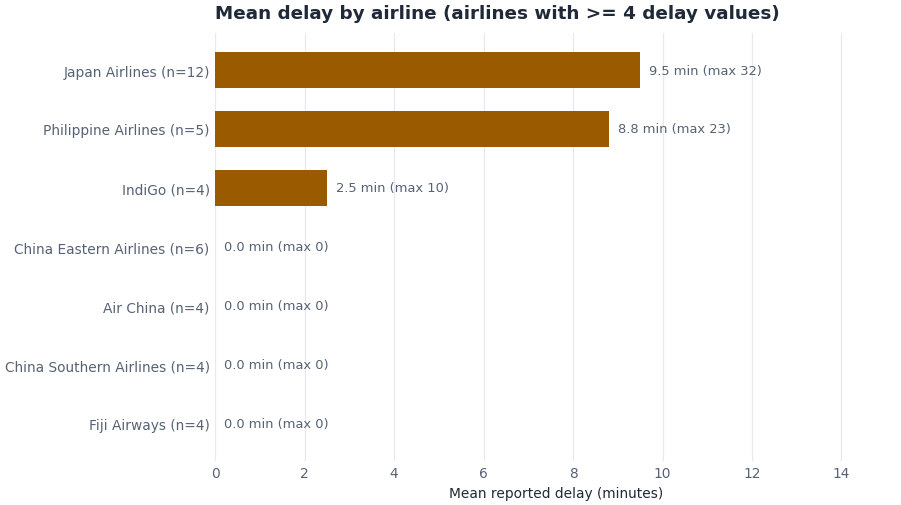

,airline_name,flights_with_delay_data,delayed,mean_delay_min,max_delay_min,delayed_pct
0,Japan Airlines,12,8,9.5,32.0,66.7
1,Philippine Airlines,5,4,8.8,23.0,80.0
2,IndiGo,4,1,2.5,10.0,25.0
3,China Eastern Airlines,6,0,0.0,0.0,0.0
4,Air China,4,0,0.0,0.0,0.0
5,China Southern Airlines,4,0,0.0,0.0,0.0
6,Fiji Airways,4,0,0.0,0.0,0.0


In [22]:
show(eda_charts.fig_delay_by_airline(df, summary))
summary["delay_by_airline"]

In [23]:
summary["delay_by_dep_airport"]

,dep_iata,flights_with_delay_data,delayed,mean_delay_min,max_delay_min,delayed_pct
0,LHW,7,1,9.29,65.0,14.3
1,RMO,8,5,7.12,15.0,62.5
2,HND,5,2,5.80,16.0,40.0
3,CGH,9,2,3.33,15.0,22.2
4,KUL,4,1,2.25,9.0,25.0
5,MEL,19,0,0.00,0.0,0.0
6,BKK,18,0,0.00,0.0,0.0
7,DOH,11,0,0.00,0.0,0.0
8,TFU,10,0,0.00,0.0,0.0
9,HRB,7,0,0.00,0.0,0.0


In [24]:
summary["status_vs_delay"]

,flight_status,flights,delay_reported,delayed,mean_delay_min
0,active,45,41,16,4.46
1,landed,1,1,0,0.00
2,scheduled,184,83,12,3.76


### 5.6 Outliers (Tukey 1.5 x IQR)
Delays are analysed for delayed flights only: most flights report 0, so the IQR of the raw column is 0 and every delayed flight would be flagged.

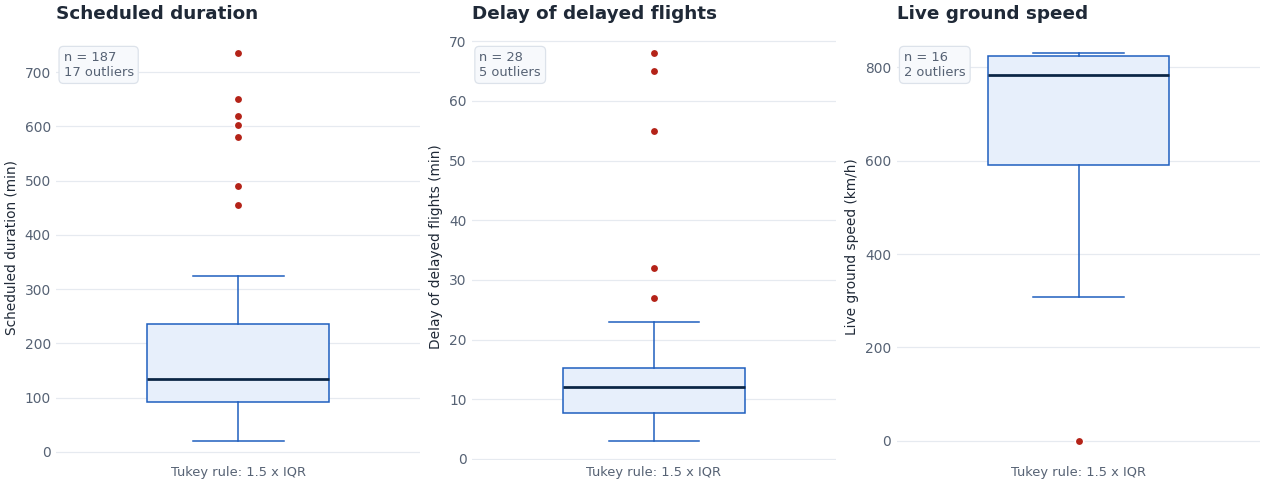

scheduled_duration_min {'column': 'scheduled_duration_min', 'positive_only': False, 'n': 187, 'q1': 92.5, 'q3': 235.0, 'iqr': 142.5, 'lower_fence': -121.25, 'upper_fence': 448.75, 'outliers': 17, 'outlier_pct': np.float64(9.1), 'median': 135.0, 'max': 735.0}
delay_min_positive {'column': 'max_delay_min', 'positive_only': True, 'n': 28, 'q1': 7.75, 'q3': 15.25, 'iqr': 7.5, 'lower_fence': -3.5, 'upper_fence': 26.5, 'outliers': 5, 'outlier_pct': np.float64(17.9), 'median': 12.0, 'max': 68.0}
live_speed_kmh {'column': 'live_speed_kmh', 'positive_only': False, 'n': 16, 'q1': 590.11, 'q3': 823.21, 'iqr': 233.1, 'lower_fence': 240.46, 'upper_fence': 1172.86, 'outliers': 2, 'outlier_pct': np.float64(12.5), 'median': 783.13, 'max': 829.7}


In [25]:
show(eda_charts.fig_outliers(df, summary))
for name, block in summary["outliers"].items():
    meta = {k: v for k, v in block.items() if k != "rows"}
    print(name, meta)

In [26]:
o = summary["outliers"]["scheduled_duration_min"]["rows"]
display(Markdown("**Longest scheduled flights (above the IQR fence)**"))
o.head(12)

**Longest scheduled flights (above the IQR fence)**

,flight_iata,airline_name,route,flight_date,scheduled_duration_min
88,C87112,Federal Airlines,MXP-ICN,2026-10-13,735.0
97,NZ282,Air New Zealand,AKL-SIN,2026-10-10,650.0
67,QF5551,Qantas,MEL-CMB,2026-10-13,620.0
63,TK6622,Turkish Airlines,MIA-IST,2026-10-13,603.0
66,TK9214,Turkish Airlines,MEL-HKG,2026-10-13,580.0
77,JL7890,Japan Airlines,MEL-SIN,2026-10-13,490.0
76,FJ5324,Fiji Airways,MEL-SIN,2026-10-13,490.0
74,AY5014,Finnair,MEL-SIN,2026-10-13,490.0
75,EK5035,Emirates,MEL-SIN,2026-10-13,490.0
82,6E4603,IndiGo,MEL-SIN,2026-10-13,490.0


In [27]:
# Compare the literal ('+00:00 is UTC') duration with the corrected one, from the raw archive.
from datetime import datetime
literal = []
for payload in payloads:
    for rec in payload["data"]:
        d, a = rec["departure"], rec["arrival"]
        if d.get("scheduled") and a.get("scheduled"):
            literal.append((datetime.fromisoformat(a["scheduled"]) - datetime.fromisoformat(d["scheduled"])).total_seconds() / 60)
lit = pd.Series(literal)
fixed = df["scheduled_duration_min"].dropna()
top = o.iloc[0]
display(Markdown(
    f"**Decision.** All {summary['outliers']['scheduled_duration_min']['outliers']} flagged flights are below the 24-hour limit of the second Pydantic gate, "
    f"so they are **kept** and flagged rather than deleted. Timezone correction matters here: read literally, the raw timestamps give a maximum scheduled duration of "
    f"**{lit.max():.0f} min**; after correction the maximum is **{fixed.max():.0f} min** "
    f"({top['flight_iata']}, {top['route']}). The correction also removes the artefact of identical-looking flights between airports in different timezones "
    "appearing far longer than they are."))

**Decision.** All 17 flagged flights are below the 24-hour limit of the second Pydantic gate, so they are **kept** and flagged rather than deleted. Timezone correction matters here: read literally, the raw timestamps give a maximum scheduled duration of **1155 min**; after correction the maximum is **735 min** (C87112, MXP-ICN). The correction also removes the artefact of identical-looking flights between airports in different timezones appearing far longer than they are.

## 6. Findings and limitations

In [28]:
for i, text in enumerate(summary["findings"], 1):
    print(f"{i}. {text}\n")

1. The database holds 230 validated flights across 3 flight dates (2026-10-09 to 2026-10-13); it is a snapshot of live data, not a time series.

2. 80.0% of flights are 'scheduled'; only 3 distinct status value(s) occur (scheduled, active, landed), so status carries little discriminating power.

3. Only 125 of 230 flights (54.3%) report a delay value, so delay statistics describe that subset and not all flights.

4. Among flights with delay data, 28 (22.4%) were delayed; the median delay is 0 min but the mean is 4.0 min and the maximum 68 min - the distribution is strongly right-skewed (skew 4.2).

5. When a delay occurs it is typically 12 min (median of delayed flights); 4 delay(s) reach 30 min or more.

6. Scheduled block time (timezone-corrected) has a median of 135 min and a maximum of 735 min; 17 flights (9.1%) lie above the IQR upper fence of 449 min. All are below the 24-hour validity limit, so they were retained and listed for review.

7. Operated flights were delayed more ofte

**Limitations (stated honestly)**  
* The database is a *snapshot* from a few API calls (free plan: ~100 requests/month), covering three flight dates - no trend or seasonality claims are possible.  
* Delay values exist for just over half of the flights; conclusions about delays apply only to that subset.  
* Delay *causes* are not provided by the API, so none are claimed.  
* Codeshare listings duplicate physical flights; counts of flights/airlines overstate distinct physical operations.  
* Some airports never report a timezone in any record, so their times could not be converted and stay NULL rather than being guessed.  
* The timestamp finding is proven on 11 flights departing UTC+8/+9; it is applied generally on the strength of the API's behaviour and the plausibility of the corrected durations.